# LAB 09 — Bias, Variance and Imbalanced Data
## Student Information
Name: Nainsy Chawla
Student ID: 023-24-0261
Section: H
GitHub:  https://github.com/Nainsy-chawla/ML_Lab_Practise
Kaggle : https://www.kaggle.com/nainsychawla
Dataset: Stroke Prediction Dataset (Kaggle)
Dataset Source: https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset

# Part 0  Setup and the Data 

In [1]:
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: C:\Users\TECHNOSELLERS\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [2]:
# import evertthing
# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data splitting and cross-validation
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_predict,
    validation_curve,
    learning_curve
)

# Preprocessing
from sklearn.preprocessing import StandardScaler

# Models
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve
)

# Resampling methods
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE

# Reproducibility
SEED = 42

print("All libraries imported successfully.")
print("SEED =", SEED)


All libraries imported successfully.
SEED = 42


In [3]:
# load the dataset 
df = pd.read_csv("healthcare-dataset-stroke-data_1.csv")

print("Shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nGender counts:")
print(df["gender"].value_counts())

print("\nStroke counts:")
print(df["stroke"].value_counts())

print("\nStroke percentages:")
print(df["stroke"].value_counts(normalize=True) * 100)

Shape: (5110, 12)

Missing values:
bmi    201
dtype: int64

Gender counts:
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

Stroke counts:
stroke
0    4861
1     249
Name: count, dtype: int64

Stroke percentages:
stroke
0    95.127202
1     4.872798
Name: proportion, dtype: float64


In [4]:
# clean the data
# Remove identifier
df = df.drop(columns=["id"])

# Check gender counts
print(df["gender"].value_counts())

# Remove gender categories with fewer than 2 rows
small_gender = df["gender"].value_counts()
small_gender = small_gender[small_gender < 2].index

df = df[~df["gender"].isin(small_gender)].copy()

# Separate target and input features
y = df["stroke"]
X = df.drop(columns=["stroke"])

# Convert text columns into numeric dummy columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Cleaned shape:", X.shape)

gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64
Cleaned shape: (5109, 15)


In [5]:
#split and fill the missing values
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

# Find numeric columns with missing values
numeric_cols = X_train.select_dtypes(include=np.number).columns

# Learn medians from training data only
medians = X_train[numeric_cols].median()

# Fill missing values using training medians
X_train[numeric_cols] = X_train[numeric_cols].fillna(medians)
X_test[numeric_cols] = X_test[numeric_cols].fillna(medians)

# Create scaled copies for Logistic Regression
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("Stroke cases in training:", int(y_train.sum()))
print("Stroke cases in testing:", int(y_test.sum()))

print("Remaining missing values in train:", X_train.isnull().sum().sum())
print("Remaining missing values in test:", X_test.isnull().sum().sum())

Training shape: (4087, 15)
Testing shape: (1022, 15)
Stroke cases in training: 199
Stroke cases in testing: 50
Remaining missing values in train: 0
Remaining missing values in test: 0


* Question  (a) : 
The data is highly imbalanced: only 249 of 5,110 patients (4.87%) had a stroke, versus 4,861 (95.13%) without. stratify=y keeps this ratio in both splits (199 strokes in train, 50 in test). With only 50 strokes in the test set, each caught or missed patient moves recall by 2 points, so recall and precision would be unstable and an unlucky split could misrepresent real performance.

# Part 1 — The Accuracy Trap 

In [6]:
# step 1
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

y_pred_base = baseline.predict(X_test)

baseline_accuracy = accuracy_score(y_test, y_pred_base)

print("Baseline Accuracy:", baseline_accuracy)

Baseline Accuracy: 0.9510763209393346


Accuracy: 0.9521
Precision: 1.0
Recall: 0.02
F1 Score: 0.0392
ROC AUC: 0.8394
PR AUC: 0.2692

Confusion Matrix:
 [[972   0]
 [ 49   1]]


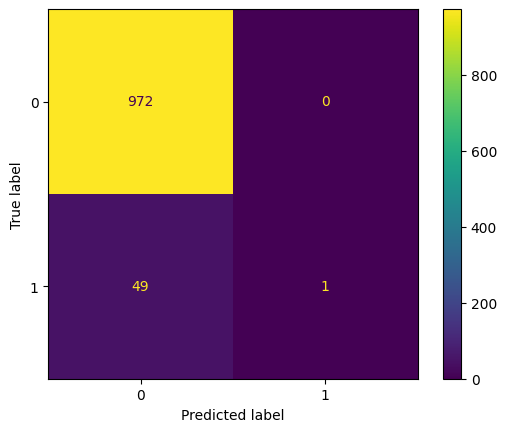

In [7]:
# step 2
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_scaled, y_train)

y_pred = lr.predict(X_test_scaled)
y_prob = lr.predict_proba(X_test_scaled)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("PR AUC:", round(average_precision_score(y_test, y_prob), 4))

cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:\n", cm)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.show()

In [8]:
# step 3
def evaluate_model(model, X_train, X_test, y_train, y_test):
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    return {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, y_prob),
        "PR AUC": average_precision_score(y_test, y_prob)
    }

# Test the helper function
results = evaluate_model(
    LogisticRegression(max_iter=1000),
    X_train_scaled, X_test_scaled,
    y_train, y_test
)

for metric, value in results.items():
    print(f"{metric}: {value:.4f}")

Accuracy: 0.9521
Precision: 1.0000
Recall: 0.0200
F1: 0.0392
ROC AUC: 0.8394
PR AUC: 0.2692


Interpretation (a): The always-“no stroke” baseline reaches accuracy 0.9511 without detecting a single stroke. Logistic Regression reaches 0.9521, only 0.001 higher, yet its recall is 0.02. Accuracy is driven almost entirely by the majority class and says little about whether the model finds strokes.

Interpretation (b):A false negative is a stroke patient predicted as “no stroke”, who would get no follow-up. The matrix [[972, 0], [49, 1]] shows only 1 of 50 strokes caught and 49 missed. We should trust recall (0.02), F1 (0.039), PR AUC (0.269 against a no-skill level of 0.049) and ROC AUC (0.839) instead of accuracy (0.952).

# Part 2 — Underfitting, Overfitting, Bias and Variance

# Task 2.1 — Validation curve 

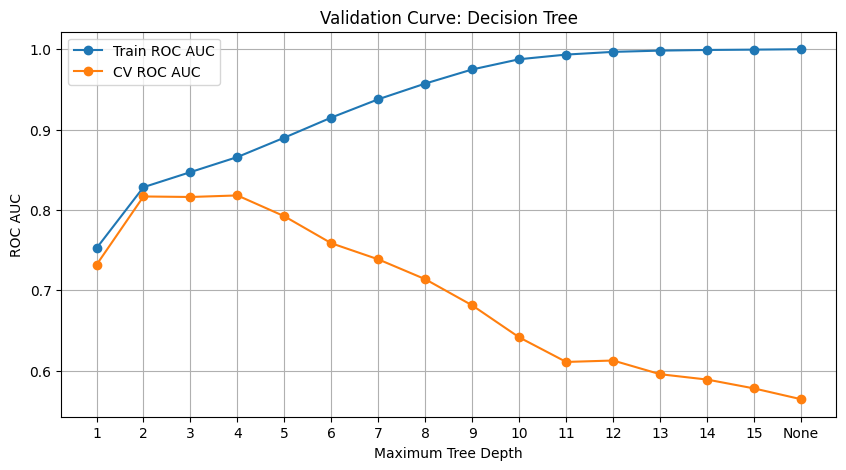

Best depth: 4
Best CV ROC AUC: 0.818


In [9]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, validation_curve
import numpy as np
import matplotlib.pyplot as plt

# 5-fold stratified cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Test different tree depths
depths = list(range(1, 16)) + [None]

# Calculate training and cross-validation ROC AUC
train_scores, cv_scores = validation_curve(
    DecisionTreeClassifier(random_state=SEED),
    X_train,
    y_train,
    param_name="max_depth",
    param_range=depths,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1
)

# Average scores across folds
train_auc = train_scores.mean(axis=1)
cv_auc = cv_scores.mean(axis=1)

# Plot both curves
depth_labels = [str(d) for d in depths]

plt.figure(figsize=(10, 5))
plt.plot(depth_labels, train_auc, marker="o", label="Train ROC AUC")
plt.plot(depth_labels, cv_auc, marker="o", label="CV ROC AUC")

plt.xlabel("Maximum Tree Depth")
plt.ylabel("ROC AUC")
plt.title("Validation Curve: Decision Tree")
plt.legend()
plt.grid(True)
plt.show()

# Find the best depth using CV AUC
best_index = np.argmax(cv_auc)

print("Best depth:", depths[best_index])
print("Best CV ROC AUC:", round(cv_auc[best_index], 4))

In [10]:
for i in range(len(depths)):
    print(
        "Depth:", depths[i],
        "| Train AUC:", round(train_auc[i], 4),
        "| CV AUC:", round(cv_auc[i], 4)
    )

Depth: 1 | Train AUC: 0.7523 | CV AUC: 0.7317
Depth: 2 | Train AUC: 0.8283 | CV AUC: 0.8168
Depth: 3 | Train AUC: 0.847 | CV AUC: 0.8161
Depth: 4 | Train AUC: 0.8658 | CV AUC: 0.818
Depth: 5 | Train AUC: 0.89 | CV AUC: 0.7921
Depth: 6 | Train AUC: 0.915 | CV AUC: 0.7585
Depth: 7 | Train AUC: 0.9377 | CV AUC: 0.7385
Depth: 8 | Train AUC: 0.9573 | CV AUC: 0.7138
Depth: 9 | Train AUC: 0.9748 | CV AUC: 0.6812
Depth: 10 | Train AUC: 0.9875 | CV AUC: 0.6414
Depth: 11 | Train AUC: 0.9933 | CV AUC: 0.6108
Depth: 12 | Train AUC: 0.9967 | CV AUC: 0.6126
Depth: 13 | Train AUC: 0.9983 | CV AUC: 0.5955
Depth: 14 | Train AUC: 0.9991 | CV AUC: 0.5889
Depth: 15 | Train AUC: 0.9995 | CV AUC: 0.5779
Depth: None | Train AUC: 1.0 | CV AUC: 0.5644


**Interpretation:**

The validation curve shows that tree depth affects how well the model generalizes to unseen data. At depth 1, the training AUC was 0.7523 and the CV AUC was 0.7317, indicating underfitting compared with the best-performing depth. Depth 4 achieved the highest CV AUC of 0.8180, with a training AUC of 0.8658, making it the best choice among the tested depths. At unlimited depth (`None`), the training AUC reached 1.0000 while the CV AUC dropped to 0.5644, showing severe overfitting.

# Task 2.2 — Learning curves 

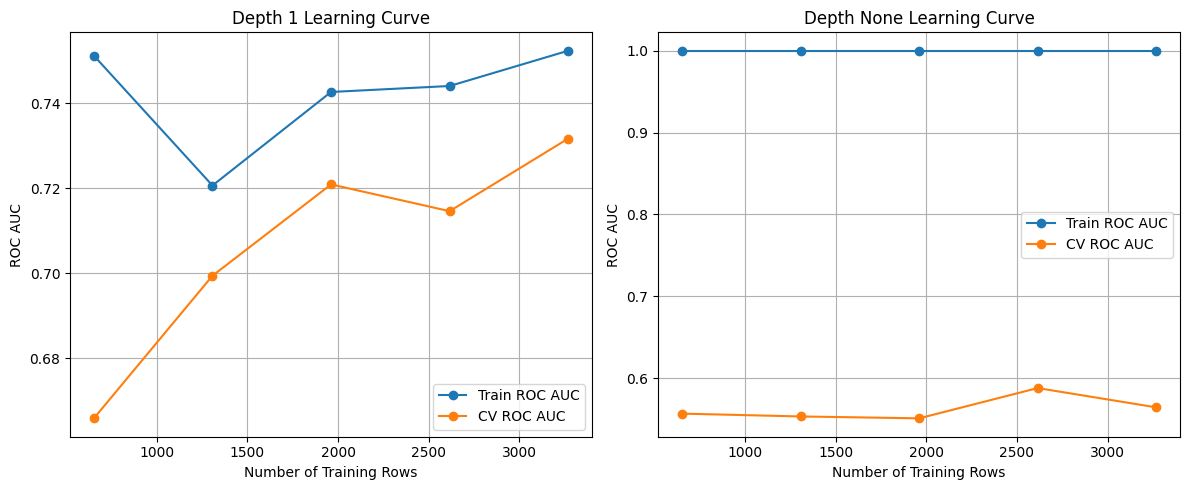

In [11]:
from sklearn.model_selection import learning_curve

# Different training set sizes from 20% to 100%
train_sizes_range = np.linspace(0.2, 1.0, 5)

# Models to compare
models = {
    "Depth 1": DecisionTreeClassifier(max_depth=1, random_state=SEED),
    "Depth None": DecisionTreeClassifier(max_depth=None, random_state=SEED)
}

plt.figure(figsize=(12, 5))

for i, (name, model) in enumerate(models.items(), start=1):

    sizes, train_scores, valid_scores = learning_curve(
        model,
        X_train,
        y_train,
        train_sizes=train_sizes_range,
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        shuffle=True,
        random_state=SEED
    )

    train_mean = train_scores.mean(axis=1)
    cv_mean = valid_scores.mean(axis=1)

    plt.subplot(1, 2, i)
    plt.plot(sizes, train_mean, marker="o", label="Train ROC AUC")
    plt.plot(sizes, cv_mean, marker="o", label="CV ROC AUC")

    plt.xlabel("Number of Training Rows")
    plt.ylabel("ROC AUC")
    plt.title(name + " Learning Curve")
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.show()

In [12]:
for name, model in models.items():

    sizes, train_scores, valid_scores = learning_curve(
        model,
        X_train,
        y_train,
        train_sizes=train_sizes_range,
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        shuffle=True,
        random_state=SEED
    )

    print("\n", name)

    for i in range(len(sizes)):
        print(
            "Rows:", sizes[i],
            "| Train AUC:", round(train_scores.mean(axis=1)[i], 4),
            "| CV AUC:", round(valid_scores.mean(axis=1)[i], 4)
        )


 Depth 1
Rows: 653 | Train AUC: 0.7512 | CV AUC: 0.6659
Rows: 1307 | Train AUC: 0.7206 | CV AUC: 0.6994
Rows: 1961 | Train AUC: 0.7426 | CV AUC: 0.7209
Rows: 2615 | Train AUC: 0.744 | CV AUC: 0.7146
Rows: 3269 | Train AUC: 0.7523 | CV AUC: 0.7317

 Depth None
Rows: 653 | Train AUC: 1.0 | CV AUC: 0.5568
Rows: 1307 | Train AUC: 1.0 | CV AUC: 0.5533
Rows: 1961 | Train AUC: 1.0 | CV AUC: 0.551
Rows: 2615 | Train AUC: 1.0 | CV AUC: 0.588
Rows: 3269 | Train AUC: 1.0 | CV AUC: 0.5644


**Interpretation:**

For depth 1, the training AUC ranged from 0.7206 to 0.7523, while the CV AUC increased overall from 0.6659 to 0.7317 as the training size increased. The two scores became closer, suggesting that adding more training data may improve generalization.

For unlimited depth, the training AUC remained 1.0000 at every training size, while the CV AUC stayed low, ranging from 0.5510 to 0.5880. This large gap indicates high variance and overfitting. More training data may help, but the results show that increasing the data size alone did not eliminate overfitting.

# Task 2.3 — Measure variance directly

In [13]:
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score

depths = [1, 3, None]
n_bootstrap = 40

rng = np.random.default_rng(SEED)
results = []

for depth in depths:

    all_probs = []
    auc_scores = []

    for i in range(n_bootstrap):

        # Draw a bootstrap sample from training data
        idx = rng.choice(
            len(X_train),
            size=len(X_train),
            replace=True
        )

        X_boot = X_train.iloc[idx]
        y_boot = y_train.iloc[idx]

        # Train a decision tree
        tree = DecisionTreeClassifier(
            max_depth=depth,
            random_state=SEED + i
        )
        tree.fit(X_boot, y_boot)

        # Predict stroke probabilities for test patients
        probs = tree.predict_proba(X_test)[:, 1]
        all_probs.append(probs)

        # ROC AUC of this individual tree
        auc_scores.append(roc_auc_score(y_test, probs))

    # Shape: 40 trees x number of test patients
    all_probs = np.array(all_probs)

    # Average variance across test patients
    avg_variance = all_probs.var(axis=0).mean()

    # Average the 40 prediction vectors
    avg_probs = all_probs.mean(axis=0)

    # ROC AUC of averaged predictions
    avg_auc = roc_auc_score(y_test, avg_probs)

    results.append({
        "Depth": str(depth),
        "Average Prediction Variance": avg_variance,
        "Mean Individual ROC AUC": np.mean(auc_scores),
        "AUC of Averaged Predictions": avg_auc
    })

In [14]:
variance_table = pd.DataFrame(results)

print(variance_table.round(4).to_string(index=False))

Depth  Average Prediction Variance  Mean Individual ROC AUC  AUC of Averaged Predictions
    1                       0.0007                   0.7623                       0.8132
    3                       0.0017                   0.7964                       0.8340
 None                       0.0418                   0.5545                       0.7534


**Interpretation:**

The average prediction variance increased with tree depth: 0.0007 for depth 1, 0.0017 for depth 3, and 0.0418 for unlimited depth. This shows that deeper trees, especially unlimited-depth trees, were more sensitive to changes in the training samples.

The mean individual-tree ROC AUC was 0.7623, 0.7964, and 0.5545 for depths 1, 3, and None, respectively. The ROC AUC of averaged predictions increased to 0.8132, 0.8340, and 0.7534, respectively. Averaging improved AUC for all three depths in this experiment. This demonstrates how combining predictions can improve stability and performance, which is the basic idea behind Random Forest.

(a) Underfitting, overfitting, and best depth

Depth 1 shows underfitting compared with the best model, with a training AUC of 0.7523 and CV AUC of 0.7317. Depth 4 is the best choice because it has the highest CV AUC of 0.8180. Unlimited depth overfits because its training AUC is 1.0000 but its CV AUC is only 0.5644.

(b) Understanding learning curves

High bias occurs when training and CV performance are both relatively low and close together. High variance occurs when training performance is much higher than CV performance. For depth 1, CV AUC improved overall as the training size increased. For unlimited depth, the large performance gap remained. More data may help reduce variance, but a high-bias model may require a more suitable model complexity.

(c) Variance and averaged predictions

Prediction variance increased from 0.0007 at depth 1 to 0.0418 at unlimited depth. The averaged predictions achieved higher ROC AUC than the mean individual trees at all three depths. Random Forest applies a similar idea by combining predictions from multiple trees to reduce the effect of individual trees' errors and improve stability.

(d) Bias–variance trade-off

The bias–variance trade-off means balancing a model that is too simple with one that is too sensitive to its training data. Depth 1 has relatively high bias and low variance. Depth 3 offers a more balanced result in this experiment, with variance of 0.0017 and mean individual-tree AUC of 0.7964. Unlimited depth has very high variance and severe overfitting, as shown by its variance of 0.0418 and CV AUC of 0.5644.

# Part 3 — ROC, AUC, Precision-Recall and Thresholds  

# Task 3.1 — Compare models with curves 

In [15]:
# Logistic Regression uses scaled data
lr = LogisticRegression(max_iter=1000, random_state=SEED)
lr.fit(X_train_scaled, y_train)

# Decision Tree uses original training data
dt = DecisionTreeClassifier(max_depth=3, random_state=SEED)
dt.fit(X_train, y_train)

# Random Forest uses original training data
rf = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    random_state=SEED
)
rf.fit(X_train, y_train)

# Predicted stroke probabilities on test data
lr_prob = lr.predict_proba(X_test_scaled)[:, 1]
dt_prob = dt.predict_proba(X_test)[:, 1]
rf_prob = rf.predict_proba(X_test)[:, 1]

models_prob = {
    "Logistic Regression": lr_prob,
    "Decision Tree (depth=3)": dt_prob,
    "Random Forest": rf_prob
}

print("Models trained successfully.")

Models trained successfully.


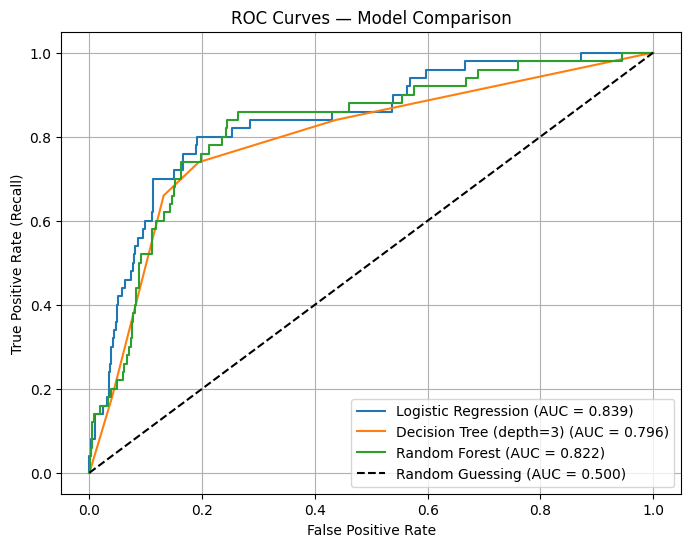

In [16]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

for name, probabilities in models_prob.items():
    fpr, tpr, thresholds = roc_curve(y_test, probabilities)
    auc_score = roc_auc_score(y_test, probabilities)

    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.3f})")

# Random-guessing line
plt.plot([0, 1], [0, 1], "k--", label="Random Guessing (AUC = 0.500)")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves — Model Comparison")
plt.legend()
plt.grid(True)
plt.show()

Interpretation : 
The ROC curve compares how well each model separates stroke and non-stroke patients at different thresholds. Logistic Regression achieved the highest ROC AUC of 0.8394, followed by Random Forest at 0.8224 and Decision Tree at 0.7956. All three models performed better than random guessing (AUC = 0.500). Therefore, Logistic Regression showed the best overall ability to distinguish between the two classes.

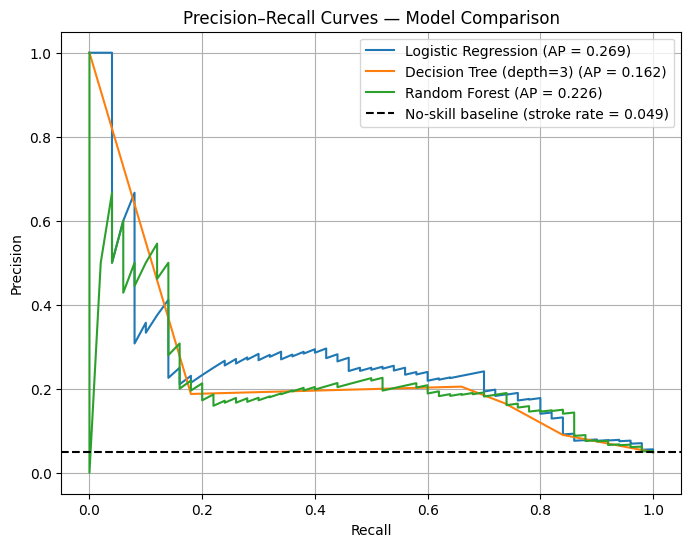

Test stroke rate: 0.0489


In [17]:
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(8, 6))

for name, probabilities in models_prob.items():
    precision, recall, thresholds = precision_recall_curve(
        y_test, probabilities
    )
    ap_score = average_precision_score(y_test, probabilities)

    plt.plot(recall, precision, label=f"{name} (AP = {ap_score:.3f})")

# No-skill baseline: proportion of stroke cases in the test set
stroke_rate = y_test.mean()

plt.axhline(
    y=stroke_rate,
    color="black",
    linestyle="--",
    label=f"No-skill baseline (stroke rate = {stroke_rate:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curves — Model Comparison")
plt.legend()
plt.grid(True)
plt.show()

print("Test stroke rate:", round(stroke_rate, 4))

Interpretation : The test dataset contains only 4.89% stroke patients, making it highly imbalanced. Logistic Regression achieved the highest Average Precision of 0.2692, followed by Random Forest at 0.2255 and Decision Tree at 0.1621. All models performed above the no-skill baseline of 0.0489. The Precision-Recall curve is especially useful here because it focuses on identifying the minority stroke class.

# Task 3.2 — Choose a decision threshold 

In [18]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_recall_curve
# Scale and train Logistic Regression within each CV fold
lr_pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=SEED)
)

# Out-of-fold probabilities using training data only
oof_prob = cross_val_predict(
    lr_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Find thresholds that achieve at least 80% training OOF recall
precision, recall, thresholds = precision_recall_curve(
    y_train, oof_prob
)

eligible_thresholds = thresholds[recall[:-1] >= 0.80]

if len(eligible_thresholds) == 0:
    raise ValueError("No threshold achieved recall >= 0.80.")

best_threshold = eligible_thresholds.max()

print("Selected threshold:", round(best_threshold, 4))
print(
    "OOF recall at selected threshold:",
    round(recall[:-1][thresholds == best_threshold][0], 4)
)

Selected threshold: 0.0509
OOF recall at selected threshold: 0.804


In [19]:
from sklearn.metrics import (
    confusion_matrix,
    recall_score,
    precision_score
)

# Fit Logistic Regression pipeline on all training data
lr_pipeline.fit(X_train, y_train)

# Predict probabilities for test patients
test_prob = lr_pipeline.predict_proba(X_test)[:, 1]

# Apply the selected threshold
test_pred_threshold = (test_prob >= best_threshold).astype(int)

# Calculate test metrics
test_recall = recall_score(
    y_test, test_pred_threshold, zero_division=0
)
test_precision = precision_score(
    y_test, test_pred_threshold, zero_division=0
)

cm_threshold = confusion_matrix(y_test, test_pred_threshold)
tn, fp, fn, tp = cm_threshold.ravel()

print("Selected threshold:", round(best_threshold, 4))
print("Test Recall:", round(test_recall, 4))
print("Test Precision:", round(test_precision, 4))
print("\nConfusion Matrix:\n", cm_threshold)
print("Patients flagged:", int(test_pred_threshold.sum()))
print("False alarms:", int(fp))
print("Missed strokes:", int(fn))

Selected threshold: 0.0509
Test Recall: 0.82
Test Precision: 0.1353

Confusion Matrix:
 [[710 262]
 [  9  41]]
Patients flagged: 303
False alarms: 262
Missed strokes: 9


In [20]:
# Show ROC AUC and Average Precision for all three models
for name, probabilities in models_prob.items():
    print(
        name,
        "| ROC AUC:", round(roc_auc_score(y_test, probabilities), 4),
        "| Average Precision:", round(
            average_precision_score(y_test, probabilities), 4
        )
    )

# Show the selected-threshold test results
print("\nThreshold:", round(best_threshold, 4))
print("Training OOF Recall:", round(
    recall[:-1][thresholds == best_threshold][0], 4
))
print("Test Recall:", round(test_recall, 4))
print("Test Precision:", round(test_precision, 4))
print("Confusion Matrix:\n", cm_threshold)
print("Patients flagged:", int(test_pred_threshold.sum()))
print("False alarms:", int(fp))
print("Missed strokes:", int(fn))

Logistic Regression | ROC AUC: 0.8394 | Average Precision: 0.2692
Decision Tree (depth=3) | ROC AUC: 0.7956 | Average Precision: 0.1621
Random Forest | ROC AUC: 0.8224 | Average Precision: 0.2255

Threshold: 0.0509
Training OOF Recall: 0.804
Test Recall: 0.82
Test Precision: 0.1353
Confusion Matrix:
 [[710 262]
 [  9  41]]
Patients flagged: 303
False alarms: 262
Missed strokes: 9


Interpretation: The selected threshold of 0.0509 achieved 80.4% recall on the training out-of-fold predictions. On the test set, recall was 82%, meaning the model detected 41 out of 50 stroke patients and missed 9. However, precision was only 13.53%, because 262 non-stroke patients were incorrectly flagged. The model flagged 303 patients in total. Lowering the threshold increased the detection of stroke patients but also increased false alarms.

(a) Why can Logistic Regression have a high ROC AUC but very low recall at threshold 0.5?

ROC AUC measures the model's ability to rank stroke patients above non-stroke patients across different thresholds. Recall at 0.5 measures performance at only one threshold. Therefore, Logistic Regression can have a high ROC AUC of 0.8394 but very low recall of 0.0200 at threshold 0.5.

(b) Precision-Recall is more informative. The no-skill line is the stroke rate, 0.049, while Logistic Regression’s AP is 0.269 (about 5.5 times higher). The PR curve also shows precision falling quickly as recall rises (0.135 at recall 0.82). ROC divides false positives by the 972 non-strokes, so 262 false alarms is only an FPR of 0.27 and looks mild.


(c) The price is 262 false alarms: 303 of 1,022 patients are flagged, about 7.4 per true stroke. In favour: a missed stroke is far more costly than a follow-up check, and missed strokes fell from 49 to 9. Against: 86% of alerts are false, which risks staff overload and alert fatigue, and 50 test strokes make these figures uncertain. It is acceptable only if the follow-up test is cheap and non-invasive.

# Part 4 — Undersampling, Oversampling and SMOTE 

# Task 4.1 — Compare the methods

In [21]:
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

samplers = {
    "No resampling": None,
    "class_weight=balanced": None,
    "Undersampling": RandomUnderSampler(random_state=SEED),
    "Oversampling": RandomOverSampler(random_state=SEED),
    "SMOTE": SMOTE(random_state=SEED),
}

def make_model(name, balanced):
    cw = "balanced" if balanced else None
    if name == "Logistic Regression":
        return LogisticRegression(max_iter=1000, class_weight=cw, random_state=SEED)
    return RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                  class_weight=cw, random_state=SEED)

rows = []
for model_name in ["Logistic Regression", "Random Forest"]:
    # LR uses scaled data, RF uses original data
    if model_name == "Logistic Regression":
        Xtr, Xte = X_train_scaled, X_test_scaled
    else:
        Xtr, Xte = X_train, X_test

    for method, sampler in samplers.items():
        if sampler is None:
            Xr, yr = Xtr, y_train
        else:
            Xr, yr = sampler.fit_resample(Xtr, y_train)   # TRAIN only

        model = make_model(model_name, method == "class_weight=balanced")
        model.fit(Xr, yr)
        pred = model.predict(Xte)
        prob = model.predict_proba(Xte)[:, 1]

        rows.append({
            "Model + Method": f"{model_name} | {method}",
            "Train rows": len(yr),
            "Train strokes": int(np.sum(yr)),
            "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred, zero_division=0),
            "F1": f1_score(y_test, pred, zero_division=0),
            "ROC AUC": roc_auc_score(y_test, prob),
            "PR AUC": average_precision_score(y_test, prob),
        })

results_4_1 = pd.DataFrame(rows)
print(results_4_1.round(4).to_string(index=False))

                             Model + Method  Train rows  Train strokes  Precision  Recall     F1  ROC AUC  PR AUC
        Logistic Regression | No resampling        4087            199     1.0000    0.02 0.0392   0.8394  0.2692
Logistic Regression | class_weight=balanced        4087            199     0.1347    0.80 0.2305   0.8395  0.2595
        Logistic Regression | Undersampling         398            199     0.1246    0.82 0.2164   0.8352  0.2338
         Logistic Regression | Oversampling        7776           3888     0.1333    0.80 0.2286   0.8385  0.2646
                Logistic Regression | SMOTE        7776           3888     0.1338    0.80 0.2292   0.8406  0.2876
              Random Forest | No resampling        4087            199     0.0000    0.00 0.0000   0.8224  0.2255
      Random Forest | class_weight=balanced        4087            199     0.2143    0.30 0.2500   0.8109  0.2088
              Random Forest | Undersampling         398            199     0.1050    0.8

(a) Logistic Regression.
Resampling and class weighting greatly improved the recall of Logistic Regression. Without resampling, the model detected very few stroke patients. After applying balancing methods, recall increased to around 80–82%. However, precision decreased because more non-stroke patients were incorrectly classified as stroke patients. ROC AUC remained almost unchanged across the methods, showing that the model's ability to rank patients was similar. SMOTE achieved the highest PR AUC of 0.2876, making it the strongest Logistic Regression option based on this metric.

(b) Random Forest reacted differently.
Random Forest reacted differently from Logistic Regression. Without resampling, it failed to detect stroke patients. Undersampling increased recall to 84%, while class weighting and oversampling achieved only 30% and 32% recall. SMOTE performed poorly, achieving only 20% recall and a PR AUC of 0.1187. This shows that resampling does not improve every model in the same way.


# Task 4.2 — The classic mistake 

In [22]:
# 1
# WRONG ORDER: SMOTE on ALL data first, then split
X_all = pd.concat([X_train, X_test])
y_all = pd.concat([y_train, y_test])

X_all_res, y_all_res = SMOTE(random_state=SEED).fit_resample(X_all, y_all)

Xw_train, Xw_test, yw_train, yw_test = train_test_split(
    X_all_res, y_all_res, test_size=0.20,
    random_state=SEED, stratify=y_all_res
)

rf_wrong = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED)
rf_wrong.fit(Xw_train, yw_train)
pw = rf_wrong.predict(Xw_test)
pw_prob = rf_wrong.predict_proba(Xw_test)[:, 1]

wrong_row = {
    "Order": "WRONG: SMOTE then split",
    "Precision": precision_score(yw_test, pw, zero_division=0),
    "Recall": recall_score(yw_test, pw, zero_division=0),
    "F1": f1_score(yw_test, pw, zero_division=0),
    "ROC AUC": roc_auc_score(yw_test, pw_prob),
    "PR AUC": average_precision_score(yw_test, pw_prob),
}
print("Wrong-order result computed.")

Wrong-order result computed.


In [23]:
#2
# CORRECT: take the RF | SMOTE row from your Task 4.1 table
c = results_4_1[results_4_1["Model + Method"] == "Random Forest | SMOTE"].iloc[0]
correct_row = {
    "Order": "CORRECT: split then SMOTE (train only)",
    "Precision": c["Precision"], "Recall": c["Recall"], "F1": c["F1"],
    "ROC AUC": c["ROC AUC"], "PR AUC": c["PR AUC"],
}

print(pd.DataFrame([wrong_row, correct_row]).round(4).to_string(index=False))

                                 Order  Precision  Recall    F1  ROC AUC  PR AUC
               WRONG: SMOTE then split     0.9094  0.9496 0.929   0.9820  0.9813
CORRECT: split then SMOTE (train only)     0.1266  0.2000 0.155   0.7668  0.1187


**Interpretation (Task 4.2):**
Applying SMOTE before the split gave Precision 0.909, Recall 0.950, F1 0.929, ROC AUC 0.982 and PR AUC 0.981.
The correct order (split first, SMOTE on train only) gave Precision 0.127, Recall 0.200, F1 0.155, ROC AUC 0.767
and PR AUC 0.119. The wrong-order model looks almost perfect, but it is not better; its test score is inflated.

(c)

The wrong-order results cannot be trusted because of data leakage. SMOTE creates synthetic minority-class samples using information from nearby minority-class examples. When SMOTE is applied before splitting, information from the future test set can influence the synthetic training samples. This allows the model to learn patterns related to the test data before evaluation. Therefore, the results become artificially high and do not represent the model's true performance on unseen patients.SMOTE builds synthetic strokes by interpolating between real stroke patients. Run before the split, it mixes the original test patients with synthetic points built from them, so the random split puts near-copies of test patients into training. The test set is also about 50% synthetic strokes instead of the real 5%, so it is easy and unrealistic. That is why precision 0.909 and ROC AUC 0.982 collapse to 0.127 and 0.767 in the correct order.

(d)

I would choose Logistic Regression with class_weight='balanced' (or equivalently, plain Logistic Regression with
a threshold chosen from out-of-fold training data, as in Task 3.2). It gave Recall 0.80, Precision 0.135 and
F1 0.2305, and its ROC AUC (0.8395) was as good as any other setup. It needs no extra data and no resampling
step that could leak. SMOTE and oversampling add about 3,700 extra rows and gave only a small PR AUC gain for LR
(0.288 vs 0.269), which is within the noise of a 50-stroke test set. For Random Forest, SMOTE made things worse
(ROC AUC 0.767), and undersampling threw away about 90% of the training rows. The cost of my choice is the same
as in Task 3.2: many false alarms (precision about 0.13), which is acceptable for a cheap screening step.

# Part 5 — Noisy Data  

# Task 5.1 — Label noise

                Logistic Regression  Decision Tree (depth=3)  \
Noise fraction                                                 
0.00                         0.8394                   0.7956   
0.05                         0.8241                   0.8014   
0.10                         0.8133                   0.8029   
0.20                         0.7743                   0.7260   

                Decision Tree (None)  Random Forest  
Noise fraction                                       
0.00                          0.5797         0.8224  
0.05                          0.5529         0.8034  
0.10                          0.5105         0.7592  
0.20                          0.5045         0.6831  


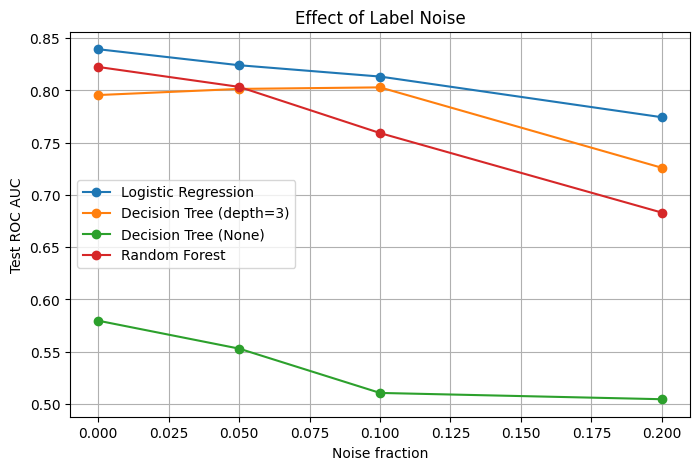

In [24]:
def flip_labels(y, fraction, rng):
    y_noisy = np.array(y, dtype=int).copy()   # writable NumPy copy
    n_flip = int(round(fraction * len(y_noisy)))
    idx = rng.choice(len(y_noisy), n_flip, replace=False)
    y_noisy[idx] = 1 - y_noisy[idx]
    return y_noisy

def get_models():
    return {
        "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
        "Decision Tree (depth=3)": DecisionTreeClassifier(max_depth=3, random_state=SEED),
        "Decision Tree (None)": DecisionTreeClassifier(max_depth=None, random_state=SEED),
        "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED),
    }

fractions = [0, 0.05, 0.10, 0.20]
label_results = {}

for frac in fractions:
    n_rep = 1 if frac == 0 else 5
    scores = {m: [] for m in get_models()}
    for r in range(n_rep):
        rng = np.random.default_rng(SEED + r)
        y_noisy = flip_labels(y_train, frac, rng)
        for name, model in get_models().items():
            if name == "Logistic Regression":
                model.fit(X_train_scaled, y_noisy)
                prob = model.predict_proba(X_test_scaled)[:, 1]
            else:
                model.fit(X_train, y_noisy)
                prob = model.predict_proba(X_test)[:, 1]
            scores[name].append(roc_auc_score(y_test, prob))
    label_results[frac] = {m: np.mean(v) for m, v in scores.items()}

label_table = pd.DataFrame(label_results).T
label_table.index.name = "Noise fraction"
print(label_table.round(4))

label_table.plot(marker="o", figsize=(8, 5))
plt.ylabel("Test ROC AUC")
plt.title("Effect of Label Noise")
plt.grid(True)
plt.show()

Interpretation (Task 5.1, label noise):
ROC AUC fell as more labels were flipped for every model. Random Forest dropped the most: 0.8224 at 0% noise
to 0.6831 at 20% (a loss of 0.139). Logistic Regression fell from 0.8394 to 0.7743 (loss 0.065), and the depth-3
tree from 0.7956 to 0.7260 (loss 0.070). The unlimited-depth tree was already near guessing (0.5797 at 0%) and
reached 0.5045 at 20%, so it has little left to lose.

# Task 5.2 — Feature noise

             Logistic Regression  Decision Tree (depth=3)  \
Noise level                                                 
0.0                       0.8394                   0.7956   
0.5                       0.8337                   0.7995   
1.0                       0.8098                   0.7610   
2.0                       0.7695                   0.6942   

             Decision Tree (None)  Random Forest  
Noise level                                       
0.0                        0.5797         0.8224  
0.5                        0.5608         0.8140  
1.0                        0.5283         0.7870  
2.0                        0.5309         0.7406  


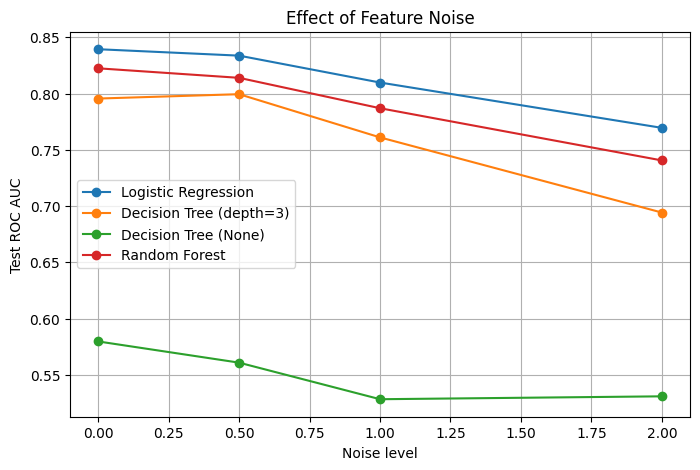

In [25]:
noise_cols = ["age", "avg_glucose_level", "bmi"]
levels = [0, 0.5, 1, 2]
feat_results = {}

for level in levels:
    n_rep = 1 if level == 0 else 5
    scores = {m: [] for m in get_models()}
    for r in range(n_rep):
        rng = np.random.default_rng(SEED + r)
        Xn = X_train.copy()
        for col in noise_cols:
            Xn[col] = Xn[col] + rng.normal(size=len(Xn)) * X_train[col].std() * level

        # scaler fitted on the NOISY training data
        sc = StandardScaler().fit(Xn)
        Xn_s, Xte_s = sc.transform(Xn), sc.transform(X_test)

        for name, model in get_models().items():
            if name == "Logistic Regression":
                model.fit(Xn_s, y_train)
                prob = model.predict_proba(Xte_s)[:, 1]
            else:
                model.fit(Xn, y_train)
                prob = model.predict_proba(X_test)[:, 1]
            scores[name].append(roc_auc_score(y_test, prob))
    feat_results[level] = {m: np.mean(v) for m, v in scores.items()}

feat_table = pd.DataFrame(feat_results).T
feat_table.index.name = "Noise level"
print(feat_table.round(4))

feat_table.plot(marker="o", figsize=(8, 5))
plt.ylabel("Test ROC AUC")
plt.title("Effect of Feature Noise")
plt.grid(True)
plt.show()

Interpretation (Task 5.2, feature noise):

At the highest level (2x the column std), Logistic Regression fell from 0.8394 to 0.7695 (loss 0.070), the
depth-3 tree from 0.7956 to 0.6942 (loss 0.101), and Random Forest from 0.8224 to 0.7406 (loss 0.082). The
unlimited tree went from 0.5797 to 0.5309 (loss 0.049) but stayed near guessing.

# Task 5.3 — SMOTE and noisy labels

In [26]:
rows = []
for model_name in ["Logistic Regression", "Random Forest"]:
    for use_smote in [False, True]:
        roc_l, pr_l = [], []
        for r in range(3):
            rng = np.random.default_rng(SEED + r)
            y_noisy = flip_labels(y_train, 0.10, rng)

            Xtr = X_train_scaled if model_name == "Logistic Regression" else X_train
            Xte = X_test_scaled if model_name == "Logistic Regression" else X_test

            if use_smote:   # SMOTE applied AFTER the noise is added
                Xr, yr = SMOTE(random_state=SEED).fit_resample(Xtr, y_noisy)
            else:
                Xr, yr = Xtr, y_noisy

            m = get_models()[model_name]
            m.fit(Xr, yr)
            prob = m.predict_proba(Xte)[:, 1]
            roc_l.append(roc_auc_score(y_test, prob))
            pr_l.append(average_precision_score(y_test, prob))
        rows.append({
            "Model": model_name,
            "SMOTE": "With" if use_smote else "Without",
            "ROC AUC": np.mean(roc_l),
            "PR AUC": np.mean(pr_l),
        })

smote_noise_table = pd.DataFrame(rows)
print(smote_noise_table.round(4).to_string(index=False))

              Model   SMOTE  ROC AUC  PR AUC
Logistic Regression Without   0.8140  0.2174
Logistic Regression    With   0.8158  0.2259
      Random Forest Without   0.7482  0.1543
      Random Forest    With   0.5967  0.0607


(a) Which model was most damaged and which was most stable?
Random Forest was affected the most by label noise. Its ROC AUC decreased from 0.8224 to 0.6831 at 20% noise, a loss of 0.1393.
Logistic Regression was the most stable useful model. Its ROC AUC decreased from 0.8394 to 0.7743, a loss of only 0.0651.
The unlimited-depth Decision Tree had the worst final result (0.5045), but it was already performing poorly because it overfitted the training data. It can easily memorize incorrect labels. Logistic Regression is simpler and learns general patterns, so it is less affected by wrong labels.


(b) Which caused more damage: label noise or feature noise?
For Random Forest, label noise caused more damage. At 10% label noise, its ROC AUC fell to 0.7592, while at feature noise level 1, it was 0.7870.
For Logistic Regression, both types of noise had a similar effect. Label noise reduced its ROC AUC by 0.026, while feature noise reduced it by 0.030.
Overall, label noise affected Random Forest more because incorrect labels teach the model the wrong answers. Feature noise changes the input values, but the model may still find useful information in other features.

(c) What happened when SMOTE was used with noisy labels?
For Logistic Regression, SMOTE made a very small improvement. ROC AUC increased from 0.8140 to 0.8158, and PR AUC increased from 0.2174 to 0.2259.
However, SMOTE badly affected Random Forest. Its ROC AUC decreased from 0.7482 to 0.5967, and PR AUC decreased from 0.1543 to 0.0607.
This happened because SMOTE creates new minority-class samples using existing minority-class examples. When some labels are incorrect, SMOTE can create more synthetic examples based on those wrong labels. Random Forest may learn these incorrect patterns, while simpler Logistic Regression is less affected.

# Part 6 — Final Decision and Conclusion 

In [27]:
final_prob = lr_pipeline.predict_proba(X_test)[:, 1]

def final_row(label, thr):
    pred = (final_prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {
        "Setting": label,
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "False alarms": int(fp),
        "Missed strokes": int(fn),
    }

final_table = pd.DataFrame([
    final_row("Default threshold 0.5", 0.5),
    final_row(f"Chosen threshold {best_threshold:.4f}", best_threshold),
])
print(final_table.round(4).to_string(index=False))

                Setting  Precision  Recall     F1  False alarms  Missed strokes
  Default threshold 0.5     1.0000    0.02 0.0392             0              49
Chosen threshold 0.0509     0.1353    0.82 0.2323           262               9


In [28]:
### Executive Summary

For this experiment, I selected Logistic Regression with a decision threshold of 0.0509.  
The model achieved 82% recall and 13.53% precision on the test set.  
It detected 41 out of 50 stroke patients and missed 9 cases.  
However, it also produced 262 false alarms, which is the cost of detecting more stroke patients.  
To avoid data leakage, I split the data before resampling and used training data only for fitting preprocessing steps and selecting the threshold through cross-validation.  
The test set was kept separate for final evaluation.  
One limitation is that the test set contained only 50 stroke patients, so the results may change with a larger dataset.  
The selected threshold also needs further validation before any real hospital use.

SyntaxError: invalid syntax (197927744.py, line 3)

# Final Reflection 

(a)
 The leakage experiment. Applying SMOTE before the split gave ROC AUC 0.982 and
recall 0.950, while the correct order gave ROC AUC 0.767 and recall 0.200 for the same Random Forest. A
tiny change in the order of two steps made a poor model look almost perfect. I was also surprised that
Logistic Regression had ROC AUC 0.84 but recall 0.02 at the default threshold: the model ranked patients well,
but the cut-off was in the wrong place.


(b)
I would try more decision thresholds and compare their precision and recall. I would also test the model using more cross-validation experiments and a larger dataset. This could help find a better balance between detecting stroke patients and reducing false alarms.